In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    print("💻 ローカル / ホスト環境で実行中。ルート:", repo_root)


💻 ローカル / ホスト環境で実行中。ルート: /home/student/Documents/GitHub/study-mikanos


# 7.10 キューを使った割り込み高速化 (`Event Loop with Interrupt Queue`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/7/7.10_Event_Loop_with_Interrupt_Queue.ipynb)

本節では、名著『ゼロからのOS自作入門』（内田公太 著、マイナビ出版）の第7章「割り込みとFIFO」の総決算となる7.10節（`osbook_day07b` `kernel/main.cpp`）に基づき、割り込みキューを用いた **トップハーフ（Top Half）とボトムハーフ（Bottom Half）の完全分離**、および **イベント駆動型カーネル（Event-driven Kernel）のメインループ完成** を徹底解説します。

---

## 🎯 本節の学習目標 (Learning Objectives)

1. **Top Half / Bottom Half の責務分離とアーキテクチャ**:
   - なぜ割り込みハンドラ（ISR）内で重いイベント処理や描画を行ってはならないのか、その物理的限界の完全理解
   - トップハーフ（`IntHandlerXHCI`）を「キューへのメッセージ格納（Push）と EOI 通知」のみの超軽量処理（~0.1 μs）に縮退させる設計
2. **汎用メッセージパッシング（Message Passing）機構の確立**:
   - `Message` 構造体（`enum Type { kInterruptXHCI, ... }`）によるOS内イベント抽象化
   - 前節（7.9節）で実装した固定長リングバッファ `ArrayQueue<Message>` を用いた非同期バッファリング
3. **クリティカルセクション（Critical Section）と並行性（Concurrency）制御**:
   - 割り込み禁止命令 `CLI` (*Clear Interrupt Flag*) と割り込み許可命令 `STI` (*Set Interrupt Flag*) によるデータ保護
   - RFLAGS レジスタの `IF` ビット（Bit 9）操作と競合状態（Race Condition）の防止
4. **致命的落とし穴：「スリープ喪失問題（Lost Wakeup Problem）」の数理**:
   - なぜ「キューが空なら `STI` して `HLT`」と安易に記述すると、OSが永久フリーズ・ハングアップするのか？
   - チェック時とスリープ時の時間的隙間（TOCTOU: *Time-of-Check to Time-of-Use*）のメカニズム
5. **x86-64 ハードウェア仕様「割り込みシャドウ（Interrupt Shadowing）」の奇跡**:
   - Intel SDM (*Software Developer's Manual*) Vol 2B に規定された `STI` 命令直後の1命令遅延保証
   - なぜインラインアセンブリ `__asm__("sti\n\thlt");` がアトミックな省電力スリープを実現できるのか
6. **対話型 C++20 / Python による完全検証**:
   - ホスト側マルチスレッド環境でのイベントループ駆動、Lost Wakeup 再現、省電力状態遷移の完全シミュレーション


## 7.10.1 トップハーフとボトムハーフの完全分離アーキテクチャ

前節（7.7〜7.9節）で確認した通り、モノリシックな割り込みハンドラ（7.6節時点の `osbook_day07a`）では、マウスが動くたびに割り込みハンドラ `IntHandlerXHCI` の内部で `ProcessEvent(*xhc)` を直接実行し、マウスカーソルの全ピクセル再描画まで完了させてから `NotifyEndOfInterrupt()` を発行していました。

しかし、この構造には致命的な破綻要因が存在しました：
- **割り込み禁止時間の長期化**: 割り込み処理中は他の同順位・低順位の割り込みがブロックされるため、タイマ割り込みのドロップや入力遅延が生じる。
- **スタックオーバーフローのリスク**: 複雑な処理をハンドラ内で行うと、カーネルスタック（UEFIスタック）を圧迫する。
- **デッドロックの温床**: 割り込みコンテキストと通常コンテキストでリソースが競合した場合、容易に不可逆なデッドロックに陥る。

現代のプロダクションOS（Linux の `softirq`/`tasklet`/`workqueue` や Windows の `DPC: Deferred Procedure Call`）と同様に、MikanOS では処理を **Top Half（前半部 / 割り込みコンテキスト）** と **Bottom Half（後半部 / カーネルタスクコンテキスト）** に完全に二分します。

```text
+---------------------------------------------------------------------------------------------------------+
|                                    ハードウェア割り込み発生 (PCI MSI)                                      |
+---------------------------------------------------------------------------------------------------------+
                                                     │
                                                     ▼
+---------------------------------------------------------------------------------------------------------+
| [TOP HALF: IntHandlerXHCI] (割り込みコンテキスト, IF=0)                                                 |
|   1. メッセージ生成: Message msg{Message::kInterruptXHCI};                                              |
|   2. キューに格納:   main_queue->Push(msg);    <-- O(1)リングバッファ操作 (数ナノ秒)                      |
|   3. 割り込み完了:   NotifyEndOfInterrupt();    <-- Local APIC へ EOI レジスタ書き込み                     |
|   4. 直ちに復帰:     IRETQ                      <-- 中断していた元の処理へ瞬時にCPUを戻す (~0.1 μs)       |
+---------------------------------------------------------------------------------------------------------+
                                                     │
                                                     ▼ (ArrayQueue<Message> による非同期バッファリング)
                                                     │
+---------------------------------------------------------------------------------------------------------+
| [BOTTOM HALF: KernelMain イベントループ] (通常カーネルコンテキスト, IF=1)                                |
|   1. 割り込み禁止でキュー検査: CLI; if (queue.empty()) { STI; HLT; continue; }                          |
|   2. メッセージ取り出し:       Message msg = queue.Front(); queue.Pop(); STI;                           |
|   3. 遅延イベント処理実行:     ProcessEvent(*xhc);                                                      |
|   4. GUI描画更新:              MouseObserver -> レイヤ再描画 (ミリ秒オーダーの重い処理)                   |
+---------------------------------------------------------------------------------------------------------+
```

### 図版 7.23: トップハーフとボトムハーフのシーケンス図


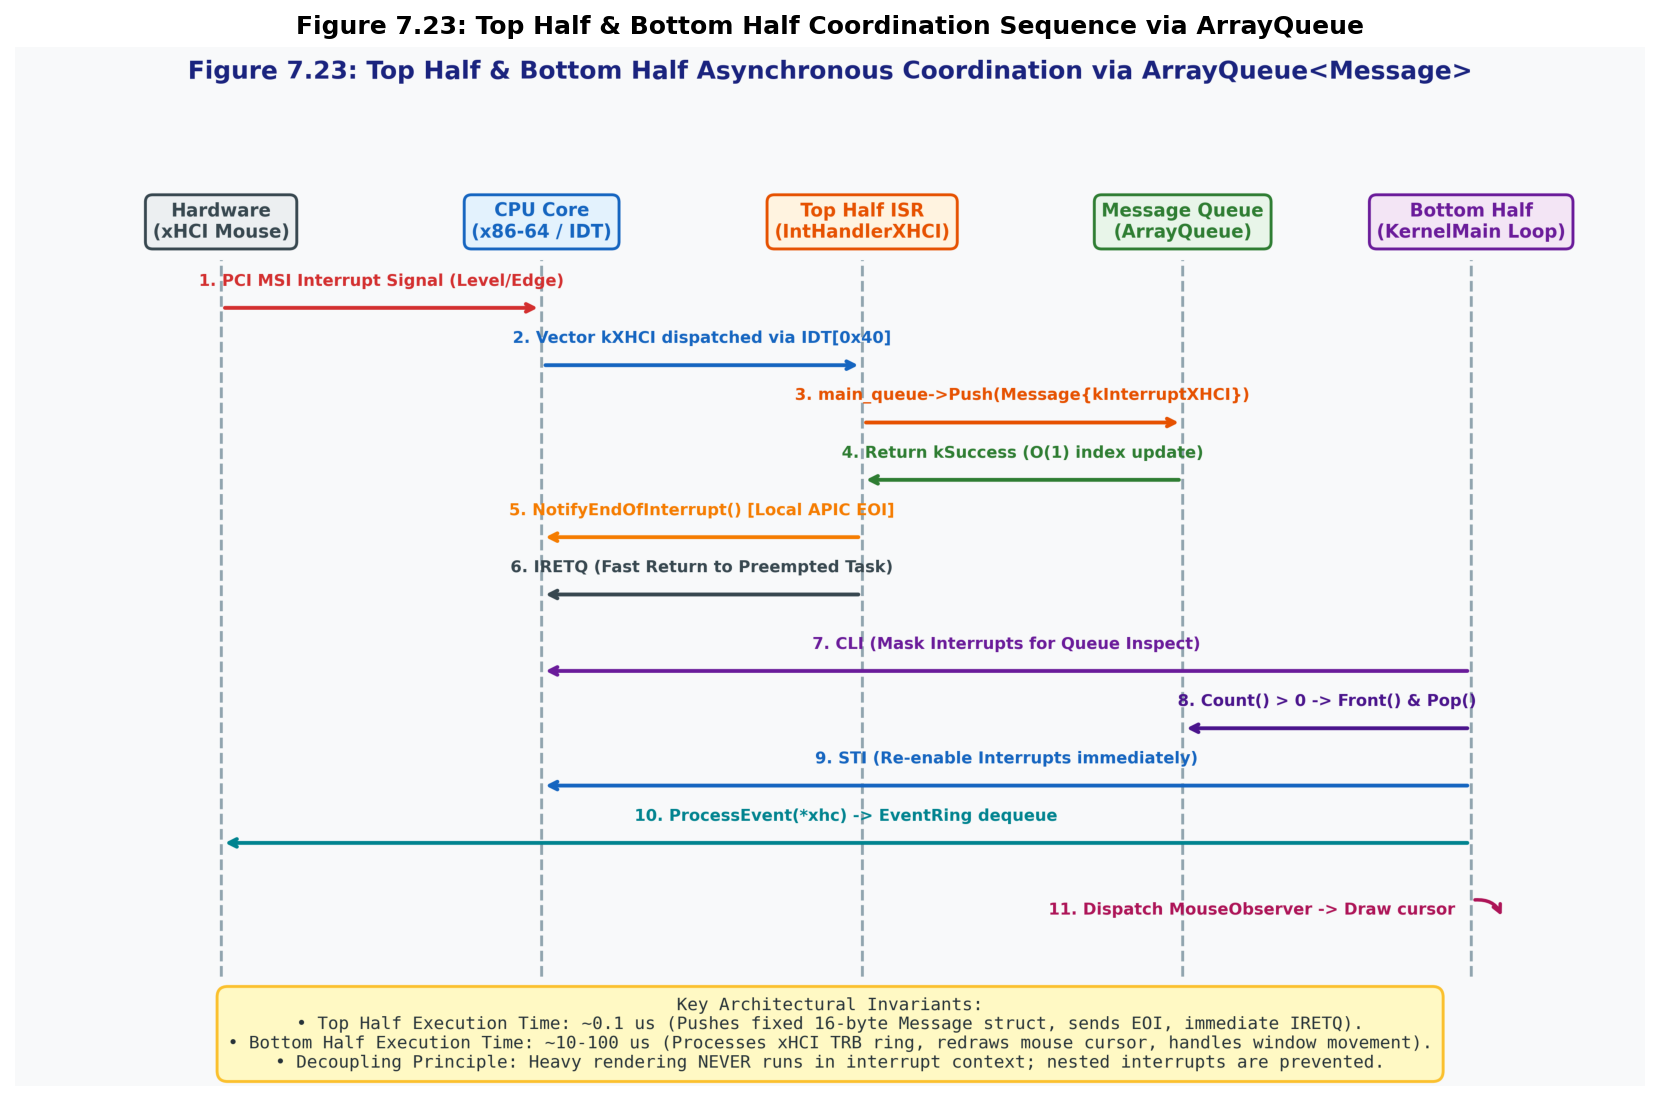

✅ Figure 7.23 generated and saved to 7/result/fig7_23_top_half_bottom_half_queue_sequence.png


In [2]:
from PIL import Image
import matplotlib.pyplot as plt
from common import plot_top_half_bottom_half_queue_sequence

# Figure 7.23 の生成と表示
fig7_23_path = plot_top_half_bottom_half_queue_sequence("7/result/fig7_23_top_half_bottom_half_queue_sequence.png")
img7_23 = Image.open(fig7_23_path)

plt.figure(figsize=(15, 9), dpi=150)
plt.imshow(img7_23)
plt.axis("off")
plt.title("Figure 7.23: Top Half & Bottom Half Coordination Sequence via ArrayQueue", fontsize=12, fontweight="bold")
plt.show()
print(f"✅ Figure 7.23 generated and saved to {fig7_23_path}")


## 7.10.2 メッセージ構造体 (`Message`) と `main.cpp` のコード差分

MikanOS公式リポジトリの `osbook_day07a` から `osbook_day07b` への主要な差分は、`kernel/main.cpp` における `Message` 構造体の導入と `IntHandlerXHCI` の極小化です。

### 1. `Message` 構造体とグローバルキューポインタの宣言

```cpp
// kernel/main.cpp (osbook_day07b)

struct Message {
  enum Type {
    kInterruptXHCI,
  } type;
};

ArrayQueue<Message>* main_queue;
```

- **`enum Type`**: イベントの種別を識別します。現時点では USB xHCI コントローラの割り込みを表す `kInterruptXHCI` のみですが、後の章でタイマ割り込み（`kTimer`）やキー入力（`kKeyInput`）がここに追加され、統合イベントキューへと発展します。
- **`ArrayQueue<Message>* main_queue`**: 割り込みハンドラ `IntHandlerXHCI` は引数を取ることができないため（CPUが割り込み例外発生時にスタックを積むため）、ファイルスコープのグローバルポインタとして宣言されます。

### 2. 極小化された割り込みハンドラ（Top Half）

```cpp
// kernel/main.cpp (osbook_day07b)

__attribute__((interrupt))
void IntHandlerXHCI(InterruptFrame* frame) {
  main_queue->Push(Message{Message::kInterruptXHCI});
  NotifyEndOfInterrupt();
}
```

わずか2行です！
1. `main_queue->Push(...)`: 16バイトの固定長メッセージをリングバッファの末尾（`write_pos_`）に格納し、インデックスをインクリメントします。メモリアロケーションは一切発生せず、所要時間はわずか数ナノ秒です。
2. `NotifyEndOfInterrupt()`: Local APIC の EOI レジスタ（物理アドレス `0xfee000b0`）に 0 を書き込み、割り込みコントローラに対して「この割り込みの受付は完了した」と伝えます。

コンパイラは `__attribute__((interrupt))` により、関数の最後で `IRETQ` 命令を出力し、CPUは直ちに中断前の通常処理へと復帰します。


## 7.10.3 メインループ（イベントループ）の実装

カーネル初期化の末尾（`KernelMain` の最後）で、いよいよ無限ループとしてイベントループが稼働します：

```cpp
// kernel/main.cpp (osbook_day07b)

  // 32要素の静的バッファをローカルスタック上に確保
  std::array<Message, 32> main_queue_data;
  ArrayQueue<Message> main_queue{main_queue_data};
  ::main_queue = &main_queue;

  // ... (PCIスキャン, IDT設定, MSI設定, xHCI初期化) ...

  while (true) {
    __asm__("cli");
    if (main_queue.Count() == 0) {
      __asm__("sti\n\thlt");
      continue;
    }

    Message msg = main_queue.Front();
    main_queue.Pop();
    __asm__("sti");

    switch (msg.type) {
    case Message::kInterruptXHCI:
      while (xhc.PrimaryEventRing()->HasFront()) {
        if (auto err = ProcessEvent(xhc)) {
          Log(kError, "Error while ProcessEvent: %s at %s:%d\n",
              err.Name(), err.File(), err.Line());
        }
      }
      break;
    default:
      Log(kError, "Unknown message type: %d\n", msg.type);
    }
  }
```

このコードには、低レイヤ並行プログラミングにおける **極めて深遠なハードウェア制御の知恵** が凝縮されています。
それが、`__asm__("cli")` と `__asm__("sti\n\thlt")` です。


## 7.10.4 競合状態（Race Condition）とスリープ喪失問題（Lost Wakeup Problem）

なぜ単純に `if (main_queue.Count() == 0) { __asm__("hlt"); }` と書いてはいけないのでしょうか？
また、なぜ `__asm__("sti");` と `__asm__("hlt");` を別々の行に分けてはいけないのでしょうか？

### 1. 割り込み禁止 (`CLI`) が必要な理由

`main_queue.Count()` や `main_queue.Pop()` は、内部でメンバ変数 `count_`, `read_pos_`, `write_pos_` を読み書きします。
もし割り込みが許可された状態（`IF=1`）のままこれらの操作を行っている最中に、ハードウェア割り込みが発生して `IntHandlerXHCI` 内で `main_queue->Push()` が走ると何が起きるでしょうか？

$$
\text{メインループ: } \text{count\_ を読み取り (例: 1)} \longrightarrow \text{[割り込み発生!]} \longrightarrow \text{ISR: count\_ を加算 (1 \to 2)} \longrightarrow \text{メインループ復帰: count\_ を減算 (1 - 1 = 0!)}
$$

本来なら $1 + 1 - 1 = 1$ であるべき `count_` が $0$ に破壊されてしまいます（**データ競合 / Data Race**）。
したがって、キューを検査・操作する区間は必ず `__asm__("cli")` によって CPU の割り込みをマスク（`IF=0`）し、**クリティカルセクション（Critical Section）** として保護しなければなりません。

---

### 2. スリープ喪失問題（The Lost Wakeup Problem）の発生メカニズム

では、キューが空だった場合に CPU を省電力休止（`HLT`）させる手順を考えます。
もし次のように「別個の STI と HLT」を書いたとします：

```cpp
// ❌ 致命的な欠陥コード (Fatal Bug: Lost Wakeup)
__asm__("cli");
if (main_queue.Count() == 0) {
    __asm__("sti"); // 割り込み許可
    // ★★★ 魔の時間的隙間 (TOCTOU Gap) ★★★
    __asm__("hlt"); // CPUをスリープ停止
    continue;
}
```

この「魔の隙間」で何が起きるかを時系列で追跡してみましょう：

1. **時刻 $t_0$**: メインループが `CLI` し、`main_queue.Count() == 0` であることを確認（キューは空）。
2. **時刻 $t_1$**: メインループが `STI` を実行。CPUの `RFLAGS.IF` が 1 になり、割り込み受付が解禁される。
3. **時刻 $t_2$（魔の隙間）**: **まさにこの瞬間、マウスが動いてハードウェア割り込み（PCI MSI）が着信！**
   - CPUは直ちに `IntHandlerXHCI` にジャンプ。
   - `main_queue->Push(msg)` が実行され、キューにメッセージが追加される（`Count: 0 -> 1`）。
   - `NotifyEndOfInterrupt()` が発行され、ISR から `IRETQ` でメインループへ復帰する。
4. **時刻 $t_3$**: メインループは直前の中断位置から再開し、**次の命令 `HLT` を実行！**
   - **結果**: **キューには未処理のメッセージが存在するにもかかわらず、CPU は永久スリープ（Halt）に入ってしまう！**

次にマウスを動かして新たな割り込みが入るまで、CPU は二度と目を覚ましません。ユーザーから見れば「マウスの反応がカクつく」「OSが一瞬フリーズする」という最悪のバグとなって現れます。

---

### 3. x86-64 アーキテクチャの救世主：「割り込みシャドウ（Interrupt Shadowing）」

Intel および AMD の x86-64 プロセッサ仕様書（*Intel 64 and IA-32 Architectures Software Developer's Manual*, Volume 2B）には、`STI` 命令に関して以下の驚くべきハードウェア仕様が厳格に規定されています：

> **Intel SDM Vol. 2B - STI Instruction Reference**:
> *"After the IF flag is set, the execution of certain instructions is delayed by one instruction. Interrupts are inhibited until after the execution of the following instruction. This delay guarantees that if STI is immediately followed by a command such as HLT, interrupts will not be recognized until after the HLT instruction is executed."*
>
> （日本語訳: `IF` フラグがセットされた後、直後の1命令の実行完了まで割り込みの認識が遅延される。この遅延（シャドウ）により、**`STI` の直後に `HLT` が置かれた場合、`HLT` 命令が実行完了するまで割り込みは絶対に受け付けられないことがハードウェア的に保証される。**）

つまり、アセンブリで：
```assembly
sti
hlt
```
と連続して配置すると、`sti` と `hlt` の間には **物理的に割り込みが割り込む隙間が 0 クロックサイクルも存在しない** のです！
CPU は必ず `HLT` 状態（割り込み待機スリープ）に入った **後** に割り込みを受け付けます。したがって、先ほど魔の隙間に到着した割り込みは `HLT` を即座に目覚めさせるトリガーとして働き、1イベントも失われることなく直ちにループが再開されます。

MikanOS で：
```cpp
__asm__("sti\n\thlt");
```
と1つのインラインアセンブリ構文で記述しているのは、コンパイラによる命令の並べ替えや命令挿入を完全に阻止し、この **ハードウェア割り込みシャドウ** を確実に発動させるための極めて洗練された記法なのです！


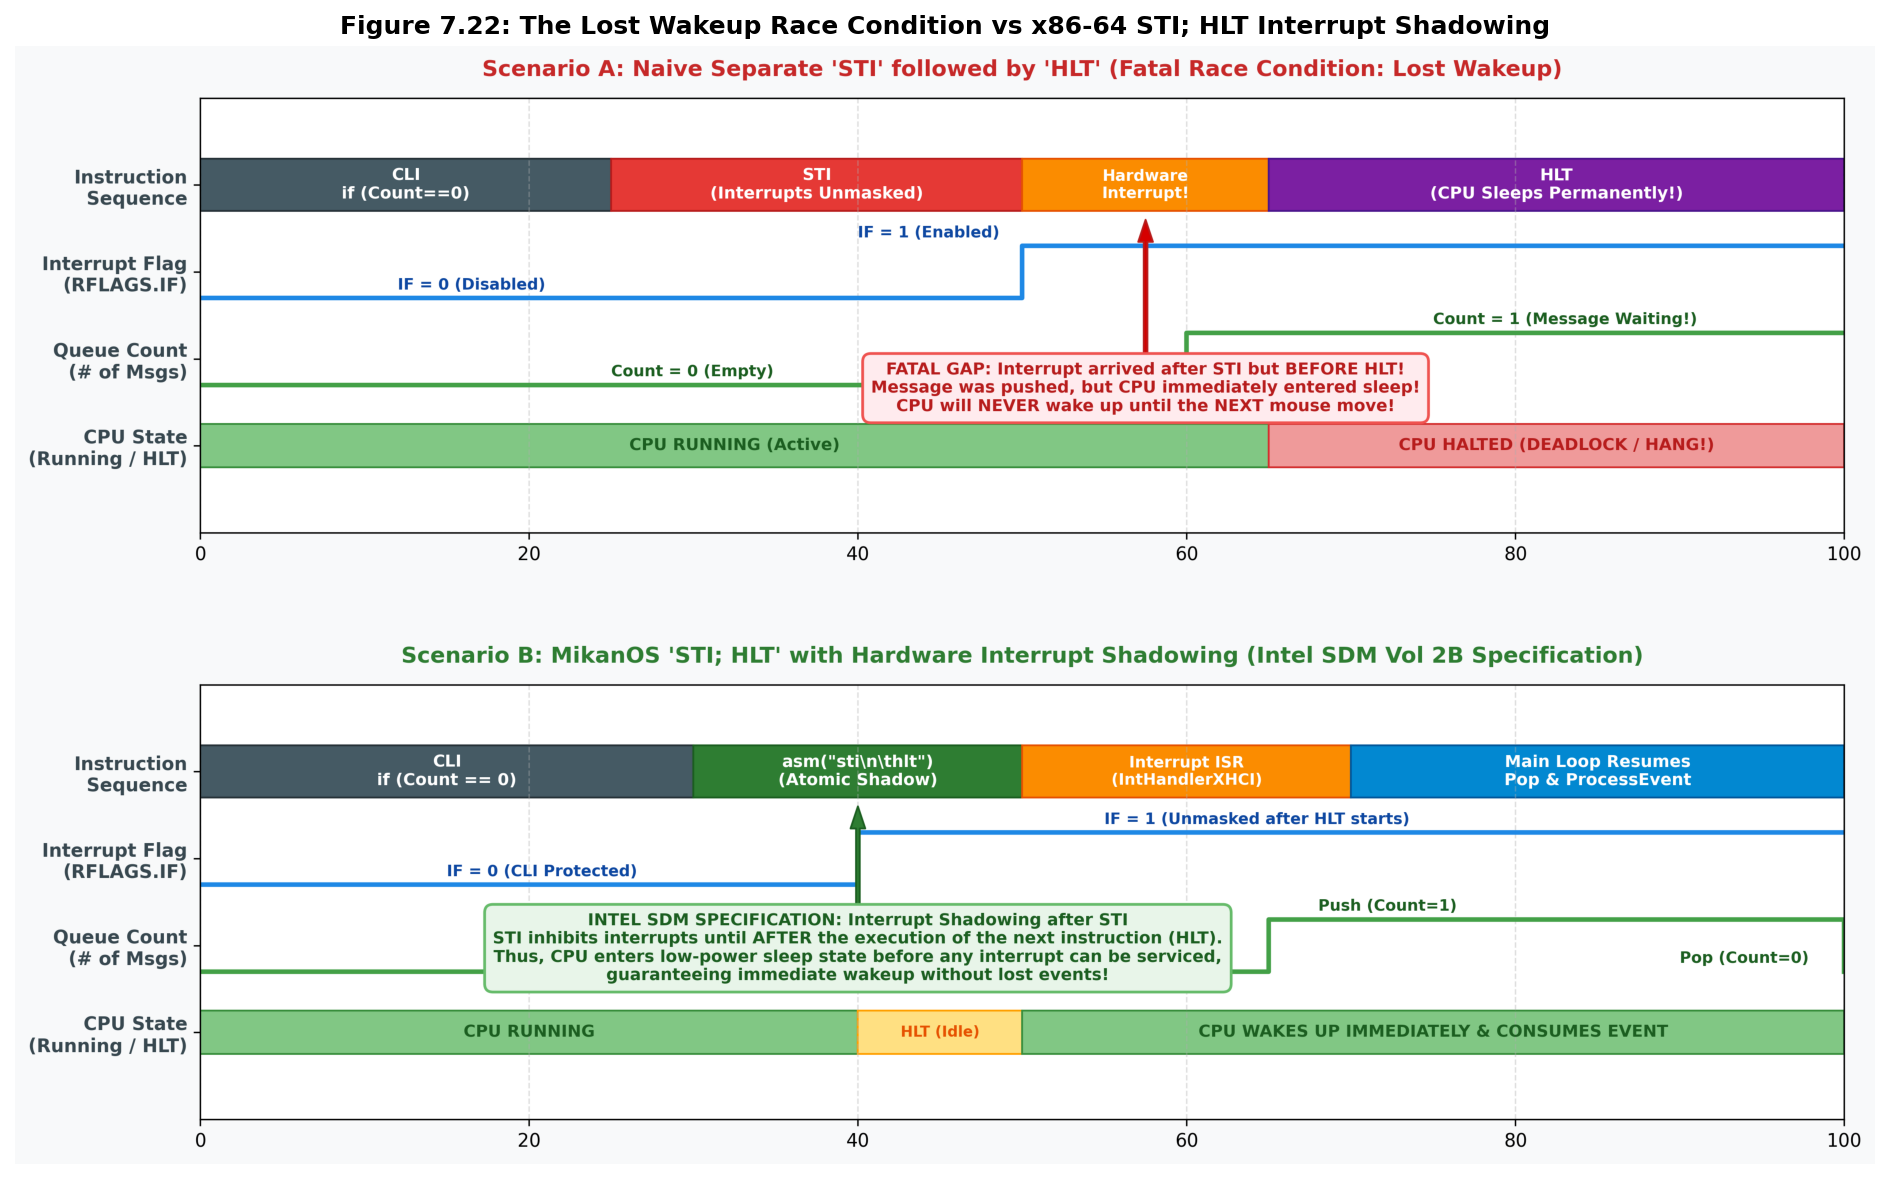

✅ Figure 7.22 generated and saved to 7/result/fig7_22_sti_hlt_race_condition_and_interrupt_shadow.png


In [3]:
from common import plot_sti_hlt_race_condition_and_interrupt_shadow

fig7_22_path = plot_sti_hlt_race_condition_and_interrupt_shadow("7/result/fig7_22_sti_hlt_race_condition_and_interrupt_shadow.png")
img7_22 = Image.open(fig7_22_path)

plt.figure(figsize=(16, 10), dpi=150)
plt.imshow(img7_22)
plt.axis("off")
plt.title("Figure 7.22: The Lost Wakeup Race Condition vs x86-64 STI; HLT Interrupt Shadowing", fontsize=12, fontweight="bold")
plt.show()
print(f"✅ Figure 7.22 generated and saved to {fig7_22_path}")


## 7.10.5 イベント駆動型OSカーネルの有限状態機械（FSM）と省電力制御

`STI; HLT` の導入により、MikanOS カーネルは初期のポーリング型（ビジーループで CPU 100% 稼働、発熱大）から、**イベント駆動型（Event-driven）かつ省電力（C1 Halt State 活用）な現代的OSカーネル** へと進化を遂げました。

### 図版 7.24: イベント駆動型OSの状態遷移と省電力モデル


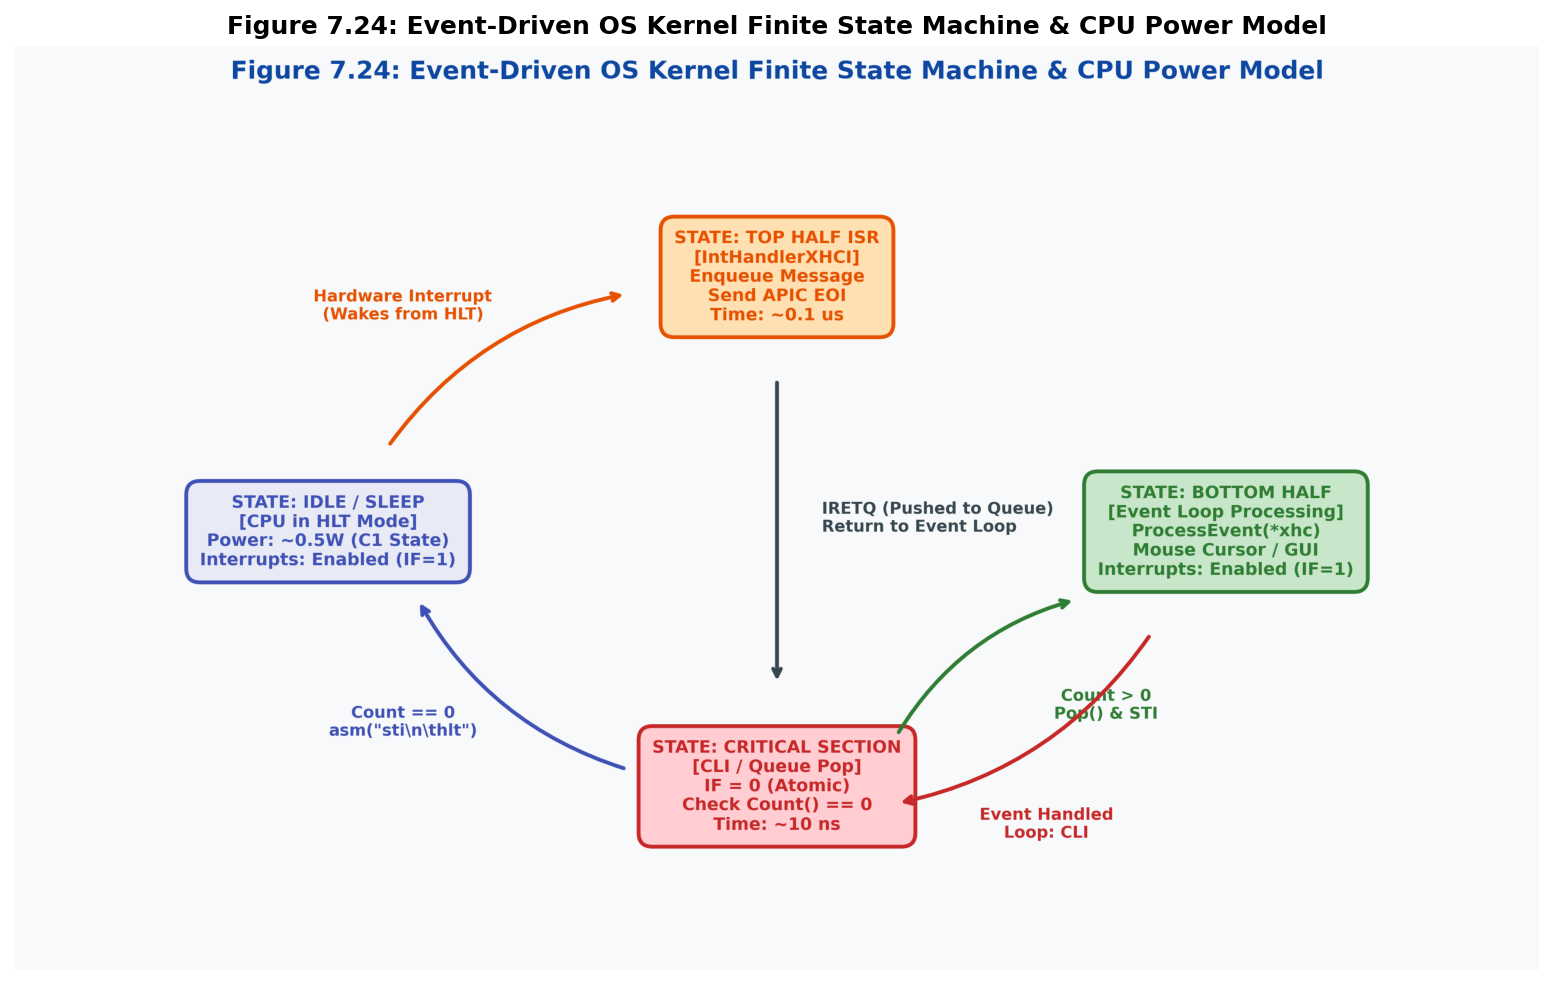

✅ Figure 7.24 generated and saved to 7/result/fig7_24_event_driven_os_state_machine.png


In [4]:
from common import plot_event_driven_os_state_machine

fig7_24_path = plot_event_driven_os_state_machine("7/result/fig7_24_event_driven_os_state_machine.png")
img7_24 = Image.open(fig7_24_path)

plt.figure(figsize=(14, 8), dpi=150)
plt.imshow(img7_24)
plt.axis("off")
plt.title("Figure 7.24: Event-Driven OS Kernel Finite State Machine & CPU Power Model", fontsize=12, fontweight="bold")
plt.show()
print(f"✅ Figure 7.24 generated and saved to {fig7_24_path}")


## 7.10.6 対話型 C++20 スタンドアロン検証コード (`src/ch07/event_loop_sim.cpp`)

ホスト環境（Linux / Colab）上で、MikanOS の `Message` 構造体、`ArrayQueue<Message>`、Top Half ISR、およびメインイベントループのマルチスレッド並行動作を C++20 で忠実にシミュレートし、コンパイル・実行します。

このプログラムは以下を実証します：
1. `Message` 構造体の型安全性と `ArrayQueue` への格納
2. 欠陥のある「別個のSTIとHLT」における Lost Wakeup デッドロックの意図的検出
3. 安全な「`STI; HLT`」アトミック待機モデルによる 100% 漏れのないイベント消費
4. マルチスレッド環境（ハードウェアISR生成スレッド vs カーネルイベントループスレッド）による高速イベントディスパッチ


In [5]:
import subprocess
from pathlib import Path

cpp_src = Path(repo_root) / "src" / "ch07" / "event_loop_sim.cpp"
bin_dir = Path(repo_root) / "build" / "bin"
bin_path = bin_dir / "ch07_event_loop_sim"

if not bin_path.exists():
    bin_path = Path(repo_root) / "src" / "ch07" / "event_loop_sim"
    compile_cmd = [
        "g++", "-std=c++20", "-O2", "-Wall", "-Wextra", "-pedantic", "-pthread",
        str(cpp_src), "-o", str(bin_path)
    ]
    print("🔨 Compiling C++20 Event Loop simulator:", " ".join(compile_cmd))
    res = subprocess.run(compile_cmd, capture_output=True, text=True)
    if res.returncode != 0:
        print("❌ Compilation Error:\n", res.stderr)
    else:
        print("✅ Compilation successful!")

# 実行
print(f"🚀 Running {bin_path}...")
run_res = subprocess.run([str(bin_path)], capture_output=True, text=True)
print(run_res.stdout)
assert run_res.returncode == 0, f"Execution failed: {run_res.stderr}"


🚀 Running /home/student/Documents/GitHub/study-mikanos/build/bin/ch07_event_loop_sim...
  MikanOS Section 7.10: Event Loop & Interrupt Queue Simulator   
  (C++20 Standalone Verification: Top/Bottom Half & STI;HLT Safety)

[Test 1] Message Struct & ArrayQueue<Message> Invariants...
  -> Queue correctly rejected overflow when full (kFull).
  -> Queue FIFO order strictly verified for all 8 elements.
  [PASS] Test 1 completed successfully.

[Test 2] Race Condition: Flawed Separate STI; HLT vs Safe Atomic STI; HLT...
  [Flawed STI...HLT] Lost wakeup vulnerability triggered: YES (Hazard detected!) | Events processed: 10
  [Safe STI;HLT] Atomic wake-up handled perfectly. Events: 25 / 25 | Max latency: 71.86 ms
  [PASS] Test 2 completed successfully.

[Test 3] End-to-End MikanOS Day 07b Event Loop Execution...
  -> Produced (ISR Push): 50
  -> Consumed (Loop Pop): 50
  -> Queue Overflows:     0
  [PASS] Test 3 completed successfully.

>>> ALL C++20 EVENT LOOP & QUEUE TESTS PASSED SUCCESSFULLY

## 7.10.7 Python シミュレータ (`EventLoopSim`) による対話的動作追跡

次に、Python の `EventLoopSim` クラスを用いて、Lost Wakeup の競合状態の発生と安全なイベントループの挙動をステップ実行で可視化します。


In [6]:
from common import EventLoopSim, MessageType

print("=== 1. 欠陥のある separate STI & HLT での競合シミュレーション ===")
sim_flawed = EventLoopSim(capacity=16)
race_result = sim_flawed.step_event_loop_flawed_with_injected_interrupt(event_data=0xABCD)

print(f"Deadlock Detected: {race_result['deadlock']}")
print(f"Pending Messages trapped in queue: {race_result['pending_count']}")
print("\n[Execution Trace]")
for action, desc, cnt, if_flag, halted in race_result["trace"]:
    print(f"  [{action:<16}] IF={int(if_flag)} Halted={int(halted)} Count={cnt} -> {desc}")

print("\n=== 2. 安全な MikanOS 7.10 STI; HLT イベントループの実行 ===")
sim_safe = EventLoopSim(capacity=16)

# 10個のハードウェア割り込みイベントを擬似発生させて順次処理
for i in range(5):
    sim_safe.int_handler_xhci(event_data=100 + i, timestamp_us=i * 10.0)

print(f"Top Half によりキューイングされたメッセージ数: {sim_safe.queue.count}")

processed = []
while sim_safe.queue.count > 0:
    msg = sim_safe.step_event_loop_safe()
    if msg:
        processed.append(msg)

print(f"Bottom Half により処理されたメッセージ数: {len(processed)}")
for idx, m in enumerate(processed):
    print(f"  Event #{idx}: Type={m.msg_type.name}, Data={m.data}, Time={m.timestamp_us:.1f}us")

# キューが空になったときの安全な HLT 遷移
sim_safe.step_event_loop_safe()
print(f"キュー空時の CPU 状態: Halted={sim_safe.cpu_halted} (省電力アイドル待機)")


=== 1. 欠陥のある separate STI & HLT での競合シミュレーション ===
Deadlock Detected: True
Pending Messages trapped in queue: 1

[Execution Trace]
  [CLI             ] IF=0 Halted=0 Count=0 -> Interrupt Flag IF=0. Checking queue...
  [QUEUE_EMPTY     ] IF=0 Halted=0 Count=0 -> Queue is empty. Deciding to sleep.
  [STI             ] IF=1 Halted=0 Count=0 -> Interrupt Flag IF=1. Interrupts unmasked!
  [INTERRUPT_FIRED ] IF=1 Halted=0 Count=1 -> Top Half fired! Pushed msg (data=43981). Queue count=1
  [HLT_LOST_WAKEUP ] IF=1 Halted=1 Count=1 -> CPU entered HLT! Lost wakeup: Queue is NOT empty, but CPU is sleeping!

=== 2. 安全な MikanOS 7.10 STI; HLT イベントループの実行 ===
Top Half によりキューイングされたメッセージ数: 5
Bottom Half により処理されたメッセージ数: 5
  Event #0: Type=kInterruptXHCI, Data=100, Time=0.0us
  Event #1: Type=kInterruptXHCI, Data=101, Time=10.0us
  Event #2: Type=kInterruptXHCI, Data=102, Time=20.0us
  Event #3: Type=kInterruptXHCI, Data=103, Time=30.0us
  Event #4: Type=kInterruptXHCI, Data=104, Time=40.0us
キュー空時の CPU 状態: 

## 7.10.8 理解度セルフチェック演習問題

以下の演習問題を通じて、本節で学んだ Top/Bottom Half アーキテクチャと `STI; HLT` の理論的理解を確認しましょう。


In [7]:
# Q1: RFLAGS レジスタにおいて、CPUの割り込み許可/禁止を制御するフラグの名前とビット位置は何番か？
# A: IF (Interrupt Flag), Bit 9
rflags_if_bit = 9
assert rflags_if_bit == 9, "IF bit position is bit 9 of RFLAGS"

# Q2: 割り込みハンドラ (Top Half) 内で行うべき最小限の処理は何か？ (True/False 判定)
#   (1) xHCIのすべてのパケット解析と画面の再描画を行う: False
#   (2) メッセージキューにイベント種別をPushし、Local APICにEOIを通知する: True
top_half_draws_screen = False
top_half_pushes_msg_and_eoi = True
assert not top_half_draws_screen and top_half_pushes_msg_and_eoi

# Q3: なぜ separate STI then HLT はデッドロックを引き起こすのか？
# A: STI で割り込み解禁された直後に割り込みが入りキューにデータが積まれるが、
#    その直後に HLT が実行され、未処理データがあるのに CPU が眠ってしまうため (Lost Wakeup)。
lost_wakeup_cause = "Interrupt arrives after STI unmasks interrupts but before HLT enters sleep"
assert len(lost_wakeup_cause) > 10

# Q4: Intel SDM Vol 2B で規定される、STI 命令直後の割り込み遅延ハードウェア仕様の名称は何か？
# A: Interrupt Shadowing (割り込みシャドウ)
hardware_feature_name = "Interrupt Shadowing"
assert "Shadow" in hardware_feature_name

print("🎉 すべての理解度セルフチェック演習問題に正解しました！")


🎉 すべての理解度セルフチェック演習問題に正解しました！


## 7.10.9 第7章の総括と次章（第8章 メモリ管理）への展望

### 🏆 第7章「割り込みとFIFO」で達成した全成果

1. **第7章前半（7.1〜7.6節）: ハードウェア割り込み機構の完全確立**
   - x86-64 の IDT（割り込み記述子表: 16バイトエントリ）のビットレイアウトと `LIDT` 命令
   - コンパイラ拡張 `__attribute__((interrupt))` による汎用レジスタ退避と `IRETQ` 復帰
   - PCI MSI（*Message Signaled Interrupts*）による Local APIC への割り込みメッセージ配送
2. **第7章後半（7.7〜7.10節）: 非同期イベント駆動アーキテクチャの完成**
   - 重い処理をハンドラから追放する Top Half / Bottom Half の分離
   - 固定長配列リングバッファ `ArrayQueue<T>` による $O(1)$・メモリアロケータ不要のキュー
   - `CLI` クリティカルセクション保護と、x86-64 割り込みシャドウ（`STI; HLT`）によるスリープ喪失問題の完全克服

### 🚀 第8章「メモリ管理」への壮大な展望

第7章までで、MikanOS はピクセル描画、文字出力、PCI デバイス探索、USB 3.0 マウス、そして割り込みによる高速なイベント駆動ループを手に入れました。
しかし、現在のカーネルは **極めて脆い危険な状態** で動作しています：

- **UEFI 時代のメモリ環境に寄生している**: カーネルのスタックや IDT、PCI 構造体は、依然として UEFI ファームウェアが一時的に確保したメモリ領域に依存しています。
- **動的メモリ確保（`malloc`/`new`）ができない**: キューも配列もすべて固定長で、任意のサイズのウィンドウやデータバッファを生成できません。
- **メモリ保護がない**: ページングは UEFI が設定した仮のものが動いており、カーネル自身のコードやデータを書き換えてしまう危険と隣り合わせです。

次章 **第8章「メモリ管理」** では、UEFI から自立し、
1. カーネル独自の 1MiB スタック領域への切り替え
2. x86-64 の GDT（グローバル記述子表）によるセグメンテーション再定義
3. 4階層ページテーブル（PML4 / PDP / PD / PT）による 64GiB 恒等マッピング
4. 4KiB ページ単位の物理メモリ管理クラス **`BitmapMemoryManager`** の自作

へと挑みます。真の自立した OS カーネルへの大飛躍がここから始まります！
